In [1]:
"""
02_content_based.py — Sistema de Recomendación Basado en Contenido
===================================================================

Este módulo implementa un sistema de recomendación Content-Based que
sugiere películas similares analizando sus características textuales:
1. TF-IDF sobre sinopsis (overview) + Similitud Coseno con linear_kernel
2. Mapeo inverso de índices (title -> index) y función get_recommendations
3. Metadata Soup (géneros + keywords + cast + director + overview) + CountVectorizer y cosine_similarity
4. Comparación de métodos y recomendaciones con filtros avanzados
5. Mapas de calor de similitud (heatmaps)
"""

'\n02_content_based.py — Sistema de Recomendación Basado en Contenido\n===================================================================\n\nEste módulo implementa un sistema de recomendación Content-Based que\nsugiere películas similares analizando sus características textuales:\n1. TF-IDF sobre sinopsis (overview) + Similitud Coseno con linear_kernel\n2. Mapeo inverso de índices (title -> index) y función get_recommendations\n3. Metadata Soup (géneros + keywords + cast + director + overview) + CountVectorizer y cosine_similarity\n4. Comparación de métodos y recomendaciones con filtros avanzados\n5. Mapas de calor de similitud (heatmaps)\n'

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity
from utils import load_and_clean_data, create_soup, fuzzy_match_title

OUTPUT_DIR = "output"
def ensure_output_dir():
    import os
    os.makedirs(OUTPUT_DIR, exist_ok=True)
ensure_output_dir()

=============================================================================
PARTE 1: TF-IDF sobre Sinopsis (Overview) y Similitud con linear_kernel
=============================================================================

In [3]:
def explain_tfidf():
    """
    Imprime una explicación teórica de TF-IDF.
    """
    print("""
    ╔══════════════════════════════════════════════════════════════════════╗
    ║                     TF-IDF: TEORÍA                                ║
    ╠══════════════════════════════════════════════════════════════════════╣
    ║                                                                    ║
    ║  TF-IDF = Term Frequency × Inverse Document Frequency              ║
    ║                                                                    ║
    ║  ┌─────────────────────────────────────────────────────────────┐   ║
    ║  │                                                            │   ║
    ║  │  TF(t,d) = frecuencia del término t en documento d         │   ║
    ║  │            ────────────────────────────────────────         │   ║
    ║  │            total de términos en documento d                 │   ║
    ║  │                                                            │   ║
    ║  │  IDF(t) = log( N / df(t) )                                 │   ║
    ║  │           N = total de documentos                          │   ║
    ║  │           df(t) = documentos que contienen t               │   ║
    ║  │                                                            │   ║
    ║  │  TF-IDF(t,d) = TF(t,d) × IDF(t)                           │   ║
    ║  │                                                            │   ║
    ║  │  → Palabras frecuentes en UN documento pero raras          │   ║
    ║  │    globalmente reciben alto score                          │   ║
    ║  │  → Palabras comunes en TODOS los documentos (the, a, is)   │   ║
    ║  │    reciben bajo score                                      │   ║
    ║  └─────────────────────────────────────────────────────────────┘   ║
    ║                                                                    ║
    ║  Ejemplo:                                                         ║
    ║    "robot" en una sinopsis de ciencia ficción → alto TF-IDF       ║
    ║    "the" en cualquier sinopsis → bajo TF-IDF (muy común)          ║
    ╚══════════════════════════════════════════════════════════════════════╝
    """)

explain_tfidf()


    ╔══════════════════════════════════════════════════════════════════════╗
    ║                     TF-IDF: TEORÍA                                ║
    ╠══════════════════════════════════════════════════════════════════════╣
    ║                                                                    ║
    ║  TF-IDF = Term Frequency × Inverse Document Frequency              ║
    ║                                                                    ║
    ║  ┌─────────────────────────────────────────────────────────────┐   ║
    ║  │                                                            │   ║
    ║  │  TF(t,d) = frecuencia del término t en documento d         │   ║
    ║  │            ────────────────────────────────────────         │   ║
    ║  │            total de términos en documento d                 │   ║
    ║  │                                                            │   ║
    ║  │  IDF(t) = log( N / df(t) )                                 │   ║
    ║  │           N = to

In [4]:
# Cargar dataset de películas y keywords
df = load_and_clean_data(include_keywords=True)

📂 Cargando movies_metadata.csv...


🔧 Parseando columnas JSON (genres, production_companies)...


🔗 Mergeando con keywords.csv...


✅ Dataset listo: 45433 películas cargadas


In [5]:
def build_tfidf_model(df):
    """
    Construye el modelo TF-IDF sobre las sinopsis de películas.
    Usa linear_kernel para similitud coseno eficiente.
    """
    print("\n🔧 Construyendo modelo TF-IDF sobre sinopsis...")

    tfidf = TfidfVectorizer(
        max_features=20000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        dtype=np.float32,
    )

    tfidf_matrix = tfidf.fit_transform(df["overview"])

    print(f"   📐 Forma de la matriz TF-IDF: {tfidf_matrix.shape}")
    print(f"   📝 Vocabulario: {len(tfidf.vocabulary_):,} términos únicos")
    print(f"   💾 Densidad de la matriz: {tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1]) * 100:.4f}%")

    print("   ⏳ Calculando similitud coseno con linear_kernel (optimizado)...")
    cosine_sim = linear_kernel(tfidf_matrix, tfidf_matrix)

    print(f"   ✅ Matriz de similitud: {cosine_sim.shape}")
    return tfidf_matrix, cosine_sim, tfidf

tfidf_matrix, cosine_sim_tfidf, tfidf_vec = build_tfidf_model(df)


🔧 Construyendo modelo TF-IDF sobre sinopsis...


   📐 Forma de la matriz TF-IDF: (45433, 20000)
   📝 Vocabulario: 20,000 términos únicos
   💾 Densidad de la matriz: 0.1329%
   ⏳ Calculando similitud coseno con linear_kernel (optimizado)...


   ✅ Matriz de similitud: (45433, 45433)


In [6]:
def get_indices_mapping(df):
    """
    Construye un mapeo inverso de títulos de películas a índices del DataFrame.
    Permite identificar directamente la fila correspondiente a cualquier título.
    """
    return pd.Series(df.index, index=df["title"]).drop_duplicates()

indices = get_indices_mapping(df)
print(f"🗺️ Mapeo inverso de índices listo: {len(indices):,} películas registradas")

def get_recommendations(title, df, cosine_sim, n=10, indices=None):
    """
    Obtiene las N películas más similares a un título dado utilizando
    mapeo inverso de índices y matriz de similitud coseno.
    """
    if indices is None:
        indices = get_indices_mapping(df)

    if title not in indices:
        matches = fuzzy_match_title(title, df["title"])
        if not matches:
            print(f"   ⚠️  No se encontró '{title}'. Intenta con otro título.")
            return pd.DataFrame()
        matched_title = matches[0]
        if matched_title.lower() != title.lower():
            print(f"   🔍 ¿Quisiste decir '{matched_title}'?")
        target_title = matched_title
    else:
        target_title = title

    idx = indices[target_title]
    if isinstance(idx, pd.Series):
        idx = idx.iloc[0]

    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:n + 1]

    movie_indices = [i[0] for i in sim_scores]
    similarity_values = [i[1] for i in sim_scores]

    results = df.iloc[movie_indices][["title", "year", "genres_str", "overview", "vote_average"]].copy()
    results["similarity"] = similarity_values
    return results.reset_index(drop=True)

def get_recommendations_tfidf(title, df, cosine_sim, n=10):
    return get_recommendations(title, df, cosine_sim, n=n)

test_movies = ["Toy Story", "The Dark Knight", "The Godfather"]
for movie in test_movies:
    print(f"\n   🎬 Recomendaciones para '{movie}' (TF-IDF + linear_kernel):")
    print("   " + "─" * 60)
    recs = get_recommendations(movie, df, cosine_sim_tfidf, n=8, indices=indices)
    if not recs.empty:
        for i, (_, row) in enumerate(recs.iterrows(), 1):
            print(f"   {i:2d}. {row['title']:<35} Sim: {row['similarity']:.3f} │ Rating: {row['vote_average']:.1f}")

🗺️ Mapeo inverso de índices listo: 45,433 películas registradas

   🎬 Recomendaciones para 'Toy Story' (TF-IDF + linear_kernel):
   ────────────────────────────────────────────────────────────
    1. Toy Story 3                         Sim: 0.443 │ Rating: 7.6
    2. Toy Story 2                         Sim: 0.367 │ Rating: 7.3
    3. Small Fry                           Sim: 0.209 │ Rating: 6.8
    4. Hot Splash                          Sim: 0.197 │ Rating: 4.0
    5. Superstar: The Life and Times of Andy Warhol Sim: 0.183 │ Rating: 0.0
    6. The 40 Year Old Virgin              Sim: 0.174 │ Rating: 6.2
    7. Ozzie                               Sim: 0.162 │ Rating: 5.0
    8. Justice League: War                 Sim: 0.148 │ Rating: 7.0

   🎬 Recomendaciones para 'The Dark Knight' (TF-IDF + linear_kernel):
   ────────────────────────────────────────────────────────────
    1. The Dark Knight Rises               Sim: 0.257 │ Rating: 7.6
    2. Batman Forever                      Sim: 0.2

=============================================================================
PARTE 2: Metadata Soup (Keywords, Cast, Director, Genres) + CountVectorizer
=============================================================================

In [7]:
def build_soup_model(df):
    """
    Construye un modelo de recomendación usando Metadata Soup
    (keywords, cast, director, géneros y sinopsis) con CountVectorizer y cosine_similarity.
    """
    print("\n🍲 Construyendo modelo con Metadata Soup...")

    df_soup = df.copy()
    df_soup["soup"] = df_soup.apply(create_soup, axis=1)

    print(f"   📝 Ejemplo de soup:")
    sample = df_soup.iloc[0]
    print(f"      Título: {sample['title']}")
    print(f"      Soup: {sample['soup'][:150]}...")

    count_vec = CountVectorizer(
        max_features=20000,
        stop_words="english",
        min_df=2,
    )
    count_matrix = count_vec.fit_transform(df_soup["soup"]).astype(np.float32)

    print(f"   📐 Forma de la matriz Count: {count_matrix.shape}")
    print(f"   📝 Vocabulario: {len(count_vec.vocabulary_):,} términos")

    print("   ⏳ Calculando similitud coseno sobre metadata soup...")
    cosine_sim_soup = cosine_similarity(count_matrix, count_matrix)

    print(f"   ✅ Matriz de similitud: {cosine_sim_soup.shape}")
    return count_matrix, cosine_sim_soup, count_vec, df_soup

count_matrix, cosine_sim_soup, count_vec, df_soup = build_soup_model(df)

for movie in test_movies:
    print(f"\n   🎬 Recomendaciones para '{movie}' (Metadata Soup):")
    print("   " + "─" * 60)
    recs = get_recommendations(movie, df, cosine_sim_soup, n=8, indices=indices)
    if not recs.empty:
        for i, (_, row) in enumerate(recs.iterrows(), 1):
            print(f"   {i:2d}. {row['title']:<35} Sim: {row['similarity']:.3f} │ Rating: {row['vote_average']:.1f}")


🍲 Construyendo modelo con Metadata Soup...


   📝 Ejemplo de soup:
      Título: Toy Story
      Soup: jealousy toy boy friendship friends rivalry boynextdoor newtoy toycomestolife jealousy toy boy friendship friends rivalry boynextdoor newtoy toycomest...


   📐 Forma de la matriz Count: (45433, 20000)
   📝 Vocabulario: 20,000 términos
   ⏳ Calculando similitud coseno sobre metadata soup...


   ✅ Matriz de similitud: (45433, 45433)

   🎬 Recomendaciones para 'Toy Story' (Metadata Soup):
   ────────────────────────────────────────────────────────────
    1. Toy Story 2                         Sim: 0.437 │ Rating: 7.3
    2. Toy Story 3                         Sim: 0.415 │ Rating: 7.6
    3. Superstar Goofy                     Sim: 0.369 │ Rating: 4.8
    4. Bobik Visiting Barbos               Sim: 0.321 │ Rating: 6.7
    5. Botsman i Popugay                   Sim: 0.320 │ Rating: 7.0
    6. Banana                              Sim: 0.310 │ Rating: 7.2
    7. Aladin                              Sim: 0.302 │ Rating: 5.5
    8. Cheburashka                         Sim: 0.302 │ Rating: 7.0

   🎬 Recomendaciones para 'The Dark Knight' (Metadata Soup):
   ────────────────────────────────────────────────────────────


    1. The Dark Knight Rises               Sim: 0.460 │ Rating: 7.6
    2. Batman Begins                       Sim: 0.445 │ Rating: 7.5
    3. Batman: Under the Red Hood          Sim: 0.437 │ Rating: 7.6
    4. Batman: Assault on Arkham           Sim: 0.388 │ Rating: 7.3
    5. Batman: The Killing Joke            Sim: 0.381 │ Rating: 6.2
    6. Batman Returns                      Sim: 0.370 │ Rating: 6.6
    7. Batman                              Sim: 0.344 │ Rating: 7.0
    8. Batman Unlimited: Monster Mayhem    Sim: 0.344 │ Rating: 6.0

   🎬 Recomendaciones para 'The Godfather' (Metadata Soup):
   ────────────────────────────────────────────────────────────
    1. Bird of Prey                        Sim: 0.431 │ Rating: 0.0
    2. A Cab for Three                     Sim: 0.431 │ Rating: 6.8
    3. Le 7ème juré                        Sim: 0.431 │ Rating: 5.8
    4. L'outremangeur                      Sim: 0.431 │ Rating: 8.0
    5. Cement                              Sim: 0.431 │ Rati

=============================================================================
PARTE 3: Comparación Lado a Lado: TF-IDF vs Metadata Soup
=============================================================================

In [8]:
def compare_methods(title, df, cosine_sim_tfidf, cosine_sim_soup, n=8):
    """
    Compara las recomendaciones de TF-IDF (solo overview) vs
    Metadata Soup (overview + genres + keywords + cast + director).
    """
    print(f"\n{'=' * 70}")
    print(f"🔬 COMPARACIÓN: TF-IDF vs Metadata Soup para '{title}'")
    print(f"{'=' * 70}")

    matches = fuzzy_match_title(title, df["title"])
    if not matches:
        print(f"   ⚠️  No se encontró '{title}'")
        return

    matched_title = matches[0]
    idx = df[df["title"] == matched_title].index[0]

    sim_tfidf = sorted(enumerate(cosine_sim_tfidf[idx]), key=lambda x: x[1], reverse=True)[1:n + 1]
    sim_soup = sorted(enumerate(cosine_sim_soup[idx]), key=lambda x: x[1], reverse=True)[1:n + 1]

    print(f"\n   {'TF-IDF (Solo Overview)':<42} │ {'Metadata Soup (Genres+KW+Overview)'}")
    print(f"   {'─' * 42}┼{'─' * 42}")

    for i in range(n):
        idx_t, score_t = sim_tfidf[i]
        idx_s, score_s = sim_soup[i]

        title_t = df.iloc[idx_t]["title"][:35]
        title_s = df.iloc[idx_s]["title"][:35]

        print(f"   {i + 1:2d}. {title_t:<35} {score_t:.3f} │ {i + 1:2d}. {title_s:<35} {score_s:.3f}")

for movie in ["Toy Story", "The Dark Knight"]:
    compare_methods(movie, df, cosine_sim_tfidf, cosine_sim_soup, n=8)


🔬 COMPARACIÓN: TF-IDF vs Metadata Soup para 'Toy Story'



   TF-IDF (Solo Overview)                     │ Metadata Soup (Genres+KW+Overview)
   ──────────────────────────────────────────┼──────────────────────────────────────────
    1. Toy Story 3                         0.443 │  1. Toy Story 2                         0.437
    2. Toy Story 2                         0.367 │  2. Toy Story 3                         0.415
    3. Small Fry                           0.209 │  3. Superstar Goofy                     0.369
    4. Hot Splash                          0.197 │  4. Bobik Visiting Barbos               0.321
    5. Superstar: The Life and Times of An 0.183 │  5. Botsman i Popugay                   0.320
    6. The 40 Year Old Virgin              0.174 │  6. Banana                              0.310
    7. Ozzie                               0.162 │  7. Aladin                              0.302
    8. Justice League: War                 0.148 │  8. Cheburashka                         0.302

🔬 COMPARACIÓN: TF-IDF vs Metadata Soup para 'The D


   TF-IDF (Solo Overview)                     │ Metadata Soup (Genres+KW+Overview)
   ──────────────────────────────────────────┼──────────────────────────────────────────
    1. The Dark Knight Rises               0.257 │  1. The Dark Knight Rises               0.460
    2. Batman Forever                      0.219 │  2. Batman Begins                       0.445
    3. Batman: Under the Red Hood          0.216 │  3. Batman: Under the Red Hood          0.437
    4. Batman Returns                      0.204 │  4. Batman: Assault on Arkham           0.388
    5. JFK                                 0.198 │  5. Batman: The Killing Joke            0.381
    6. Batman                              0.189 │  6. Batman Returns                      0.370
    7. Batman vs Dracula                   0.187 │  7. Batman                              0.344
    8. Batman: The Killing Joke            0.183 │  8. Batman Unlimited: Monster Mayhem    0.344


=============================================================================
PARTE 4: Recomendador con Filtros Avanzados
=============================================================================

In [9]:
def get_recommendations_advanced(title, df, cosine_sim, n=10,
                                  genre_filter=None, min_year=None,
                                  min_rating=0.0):
    """
    Recomendador avanzado con soporte para filtros de género, año y rating mínimo.
    """
    matches = fuzzy_match_title(title, df["title"])
    if not matches:
        print(f"   ⚠️  No se encontró '{title}'")
        return pd.DataFrame()

    matched_title = matches[0]
    idx = df[df["title"] == matched_title].index[0]

    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:]

    results = []
    for movie_idx, score in sim_scores:
        if len(results) >= n:
            break
        row = df.iloc[movie_idx]

        if genre_filter and genre_filter not in row["genres_list"]:
            continue
        if min_year and (pd.isna(row["year"]) or row["year"] < min_year):
            continue
        if row["vote_average"] < min_rating:
            continue

        results.append({
            "title": row["title"],
            "year": row["year"],
            "genres": row["genres_str"],
            "rating": row["vote_average"],
            "similarity": score,
        })

    return pd.DataFrame(results)

print(f"\n{'=' * 70}")
print("🔧 RECOMENDACIONES CON FILTROS AVANZADOS")
print(f"{'=' * 70}")
print("\n   🎬 Películas similares a 'The Dark Knight' (solo Action, post-2000, rating≥7):")
print("   " + "─" * 60)
filtered = get_recommendations_advanced(
    "The Dark Knight", df, cosine_sim_soup,
    n=10, genre_filter="Action", min_year=2000, min_rating=7.0
)
if not filtered.empty:
    for i, (_, row) in enumerate(filtered.iterrows(), 1):
        year_str = f" ({int(row['year'])})" if pd.notna(row["year"]) else ""
        print(f"   {i:2d}. {row['title']}{year_str:<35} Sim: {row['similarity']:.3f} │ Rating: {row['rating']:.1f}")


🔧 RECOMENDACIONES CON FILTROS AVANZADOS

   🎬 Películas similares a 'The Dark Knight' (solo Action, post-2000, rating≥7):
   ────────────────────────────────────────────────────────────


    1. The Dark Knight Rises (2012)                             Sim: 0.460 │ Rating: 7.6
    2. Batman Begins (2005)                             Sim: 0.445 │ Rating: 7.5
    3. Batman: Under the Red Hood (2010)                             Sim: 0.437 │ Rating: 7.6
    4. Batman: Assault on Arkham (2014)                             Sim: 0.388 │ Rating: 7.3
    5. İtirazım Var (2014)                             Sim: 0.329 │ Rating: 7.1
    6. LEGO DC Comics Super Heroes: Justice League - Gotham City Breakout (2016)                             Sim: 0.309 │ Rating: 7.0
    7. Batman Beyond Darwyn Cooke's Batman 75th Anniversary Short (2014)                             Sim: 0.304 │ Rating: 7.7
    8. The Lego Batman Movie (2017)                             Sim: 0.294 │ Rating: 7.2
    9. Batman: The Dark Knight Returns, Part 2 (2013)                             Sim: 0.291 │ Rating: 7.9
   10. Pitbull (2005)                             Sim: 0.288 │ Rating: 8.2


=============================================================================
PARTE 5: Mapas de Calor de Similitud (Heatmaps)
=============================================================================

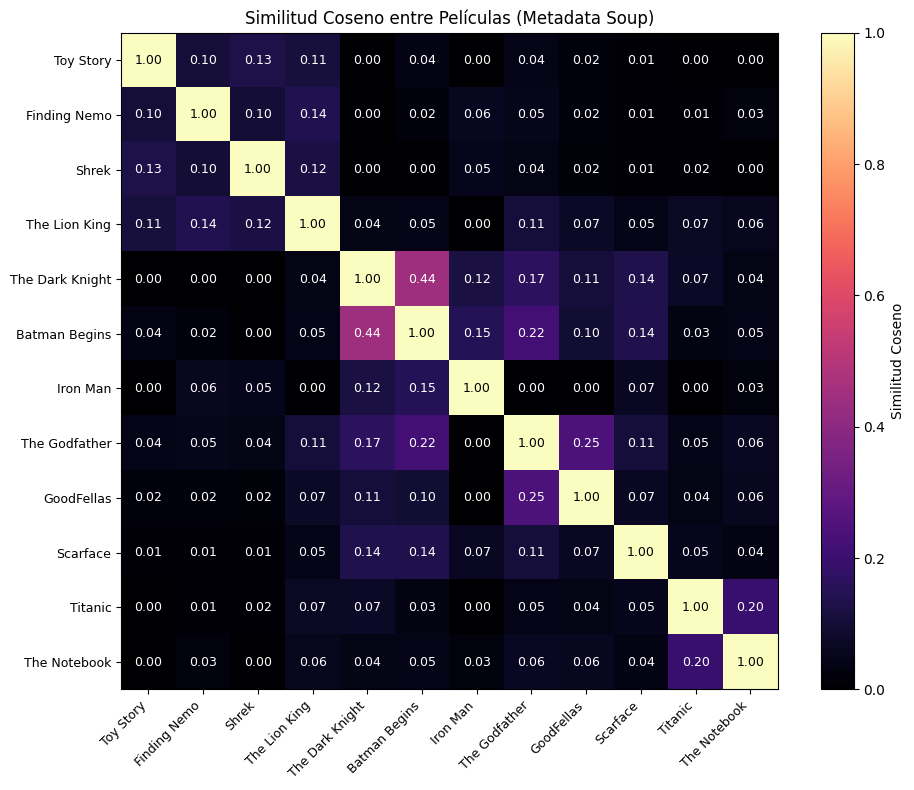

   💾 Guardado: output/02_heatmap_similitud_metadata_soup.png


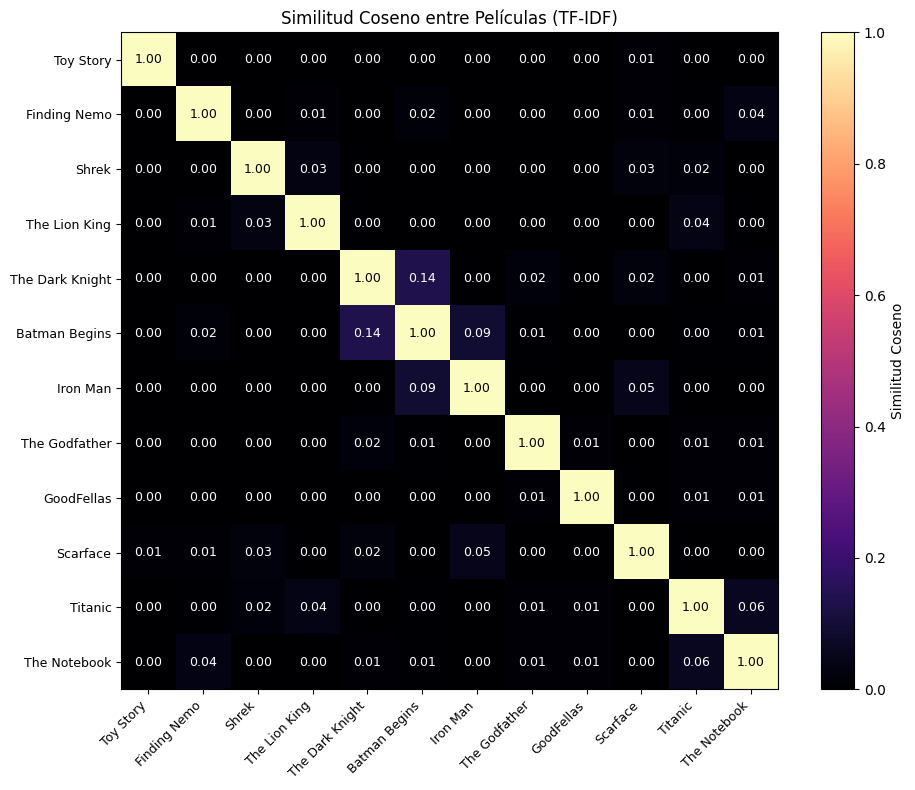

   💾 Guardado: output/02_heatmap_similitud_tf-idf.png


In [10]:
def visualize_similarity_heatmap(titles, df, cosine_sim, method_name="TF-IDF"):
    """
    Genera un heatmap de similitud coseno entre un conjunto seleccionado de películas.
    """
    ensure_output_dir()
    indices_list = []
    valid_titles = []
    for t in titles:
        matches = fuzzy_match_title(t, df["title"])
        if matches:
            idx = df[df["title"] == matches[0]].index[0]
            indices_list.append(idx)
            valid_titles.append(matches[0])

    if len(indices_list) < 2:
        print("   ⚠️  Se necesitan al menos 2 películas válidas para el heatmap")
        return

    sim_sub = cosine_sim[np.ix_(indices_list, indices_list)]

    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(sim_sub, cmap="magma", vmin=0, vmax=1)

    short_titles = [t[:25] for t in valid_titles]
    ax.set_xticks(range(len(short_titles)))
    ax.set_yticks(range(len(short_titles)))
    ax.set_xticklabels(short_titles, rotation=45, ha="right", fontsize=9)
    ax.set_yticklabels(short_titles, fontsize=9)

    for i in range(len(indices_list)):
        for j in range(len(indices_list)):
            color = "white" if sim_sub[i, j] < 0.5 else "black"
            ax.text(j, i, f"{sim_sub[i, j]:.2f}", ha="center", va="center",
                    color=color, fontsize=9)

    ax.set_title(f"Similitud Coseno entre Películas ({method_name})")
    plt.colorbar(im, label="Similitud Coseno")
    plt.tight_layout()

    path = f"{OUTPUT_DIR}/02_heatmap_similitud_{method_name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"   💾 Guardado: {path}")

comparison_movies = [
    "Toy Story", "Finding Nemo", "Shrek", "The Lion King",
    "The Dark Knight", "Batman Begins", "Iron Man",
    "The Godfather", "Goodfellas", "Scarface",
    "Titanic", "The Notebook",
]

visualize_similarity_heatmap(comparison_movies, df, cosine_sim_soup, "Metadata Soup")
visualize_similarity_heatmap(comparison_movies, df, cosine_sim_tfidf, "TF-IDF")

In [11]:
print("\n" + "=" * 70)
print("✅ Módulo 02 completado exitosamente. Visualizaciones generadas en output/")
print("=" * 70)


✅ Módulo 02 completado exitosamente. Visualizaciones generadas en output/
